# Cadena completa con lazo de Nb

Simulación de lo que mide el analizador cuando se unen dos canales con una pieza de Nb en el
portamuestras (A+ con B+, A− con B−), sin nada conectado entre + y −.

```
generador → ambiente A → crio A → pieza de Nb → crio B → ambiente B → analizador
```

El objetivo es ver cuánto influye la resistencia de la pieza de Nb. En frío es superconductora
(0 Ω), pero en caliente tiene una resistencia que depende de su largo y su diámetro. El tamaño
de la pieza se define en los parámetros (`L_nb` y `d_nb`).

## 1. Parámetros

Librerías (numpy para las cuentas, matplotlib para graficar, pandas para las tablas y brentq
para buscar la $f_c$) y estilo de los gráficos.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.optimize import brentq

# Estilo de los gráficos: fondo blanco y colores fijos
plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "lines.linewidth": 2,
    "axes.prop_cycle": plt.cycler(color=[
        "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6"]),
})

def cuadricula(ax):
    '''Cuadrícula: líneas principales gris claro, secundarias más suaves.'''
    ax.grid(which="major", color="#cccccc", linewidth=0.8)
    ax.grid(which="minor", color="#ececec", linewidth=0.5)

Valores del circuito: las 6 configuraciones del filtro ambiente, cuál usa cada canal
(`AMB_A`, `AMB_B`), el filtro crio, los 50 Ω de los instrumentos y el alambre de Nb. Al final
se calcula la resistencia del Nb en caliente.

In [2]:
# --- Filtro ambiente: las 6 configuraciones (R por resistencia, C por capacitor) ---
CONFIGS_AMB = {
    "150 Ω / 2,2 µF": (150.0, 2.2e-6),
    "150 Ω / 1 µF":   (150.0, 1.0e-6),
    "51 Ω / 2,2 µF":  (51.0,  2.2e-6),
    "51 Ω / 1 µF":    (51.0,  1.0e-6),
    "15 Ω / 2,2 µF":  (15.0,  2.2e-6),
    "15 Ω / 1 µF":    (15.0,  1.0e-6),
}
AMB_A = "15 Ω / 1 µF"     # configuración del canal A (por donde entra el generador)
AMB_B = "15 Ω / 1 µF"     # configuración del canal B (por donde sale al analizador)

# --- Filtro criogénico (igual en todos los canales) ---
R_cry = 22.0      # Ω, cada una de las 3 resistencias en serie por línea
C_cry = 47e-9     # F, cada uno de los 2 capacitores entre + y −

# --- Instrumentos ---
V_gen = 1.0       # V
R_gen = 50.0      # Ω, resistencia interna del generador
R_an = 50.0       # Ω, impedancia de entrada del analizador

# --- Alambre de Nb ---
rho_nb = 15e-8    # Ω·m (= 15 µΩ·cm, a temperatura ambiente)
L_nb = 2e-2       # m
d_nb = 50e-6      # m

# --- Barrido y gráficos ---
f = np.logspace(-1, 6, 701)     # 0,1 Hz a 1 MHz, 100 puntos por década
F_BAJA = 0.1                    # Hz: frecuencia de referencia para el nivel "de continua"
PISO_RUIDO_dB = -90.0           # dB, piso de ruido del analizador (gráfico 4)

ABIERTO = np.inf                # para pedir R_L abierta (sin carga)

# Resistencia del Nb: 0 en frío (superconductor), rho·L/A en caliente
R_nb_caliente = rho_nb * L_nb / (np.pi * d_nb**2 / 4)
R_nb_frio = 0.0
print(f"R_nb en caliente = {R_nb_caliente:.3f} Ω por alambre")

R_nb en caliente = 1.528 Ω por alambre


## 2. Modelo

La función `resolver` recibe la lista de componentes (qué está conectado con qué) y calcula
los voltajes de todos los nodos del circuito a una frecuencia, con las leyes de Kirchhoff.

In [3]:
def resolver(frec, componentes, cables, fuente, salida):
    '''Resuelve el circuito a una frecuencia y devuelve el voltaje de salida (complejo).

    componentes: lista de (nodo_a, nodo_b, Z), con Z un número o una función de w
                 (para los capacitores). Z = inf se ignora (circuito abierto).
    cables:      lista de (nodo_a, nodo_b) unidos sin resistencia (= mismo nodo).
    fuente:      (nodo_+, nodo_-, V, R_serie) -> generador de Thévenin.
    salida:      (nodo_+, nodo_-) entre los que se mide el voltaje.
    '''
    w = 2 * np.pi * frec

    # --- Unir los nodos conectados por cables ---
    # 'jefe' dice a qué nodo representativo pertenece cada nombre.
    jefe = {}
    def representante(nodo):
        jefe.setdefault(nodo, nodo)
        while jefe[nodo] != nodo:
            nodo = jefe[nodo]
        return nodo
    for a, b in cables:
        ra, rb = representante(a), representante(b)
        if ra != rb:
            if rb == "GND":          # si uno de los dos es tierra, que mande tierra
                ra, rb = rb, ra
            jefe[rb] = ra

    # --- Numerar los nodos (tierra es el 0) ---
    numero = {}
    def indice(nodo):
        r = representante(nodo)
        if r not in numero:
            numero[r] = len(numero)
        return numero[r]
    indice("GND")

    # --- Lista de admitancias ---
    admitancias = []
    for a, b, Z in componentes:
        z = Z(w) if callable(Z) else Z
        if np.isinf(z):
            continue                              # abierto: no conecta nada
        admitancias.append((indice(a), indice(b), 1 / z))
    f_mas, f_menos, V, R_serie = fuente
    admitancias.append((indice(f_mas), indice(f_menos), 1 / R_serie))   # R interna (Norton)

    # --- Matriz de admitancias y vector de corrientes ---
    N = len(numero)
    Y = np.zeros((N, N), dtype=complex)
    for i, j, y in admitancias:
        if i == j:
            continue                              # componente en corto: no aporta
        Y[i, i] += y
        Y[j, j] += y
        Y[i, j] -= y
        Y[j, i] -= y
    I = np.zeros(N, dtype=complex)
    I[indice(f_mas)] += V / R_serie
    I[indice(f_menos)] -= V / R_serie

    # --- Resolver con tierra (nodo 0) como referencia ---
    resto = list(range(1, N))
    Vn = np.zeros(N, dtype=complex)
    Vn[resto] = np.linalg.solve(Y[np.ix_(resto, resto)], I[resto])
    return Vn[indice(salida[0])] - Vn[indice(salida[1])]


def Z_cap(C):
    '''Devuelve la impedancia de un capacitor como función de w.'''
    return lambda w: 1 / (1j * w * C)

Armado del circuito. `agregar_ambiente` agrega un filtro ambiente en una línea (R, C a tierra,
R, C a tierra) y `agregar_criogenico` un filtro crio (3 R por línea y 2 C entre + y −).
`H_cadena` junta todo (generador → ambiente A → crio A → Nb → crio B → ambiente B →
analizador) y devuelve la señal que llega al analizador. También acepta una carga $R_L$ entre
+ y −, pero en este notebook se usa siempre sin carga (`ABIERTO`).

In [4]:
def agregar_ambiente(comps, canal, linea, R, C, entrada, salida):
    '''Filtro ambiente de UNA línea: entrada -R- n1 -R- salida, con C a tierra en n1 y en salida.
    El segundo C queda del lado de 'salida' (hacia el criostato).'''
    n1 = f"amb{canal}1{linea}"
    comps += [
        (entrada, n1, R),
        (n1, "GND", Z_cap(C)),
        (n1, salida, R),
        (salida, "GND", Z_cap(C)),
    ]

def agregar_criogenico(comps, canal):
    '''Filtro criogénico de un canal: 3 R de 22 Ω por línea, 2 C ENTRE líneas.'''
    for linea in ["+", "-"]:
        comps += [
            (f"{canal}ci{linea}", f"{canal}c1{linea}", R_cry),
            (f"{canal}c1{linea}", f"{canal}c2{linea}", R_cry),
            (f"{canal}c2{linea}", f"{canal}pm{linea}", R_cry),
        ]
    comps += [
        (f"{canal}c1+", f"{canal}c1-", Z_cap(C_cry)),   # después de la 1ª R
        (f"{canal}c2+", f"{canal}c2-", Z_cap(C_cry)),   # después de la 2ª R
    ]


def H_cadena(frec, R_L, R_nb=0.0, amb_A=None, amb_B=None, modo="malla", crio=True):
    '''Transferencia H = 2·V_an/V_gen de la cadena completa.

    R_L:   carga en el portamuestras (0 = corto, ABIERTO = sin carga).
    R_nb:  resistencia de cada alambre de Nb (0 = superconductor).
    amb_A, amb_B: nombre de la configuración ambiente de cada canal.
    modo:  "malla" = como se mide (A− y B− a tierra), "diferencial" = instrumentos flotantes.
    crio:  False reemplaza los dos filtros criogénicos por cables.
    '''
    amb_A = AMB_A if amb_A is None else amb_A
    amb_B = AMB_B if amb_B is None else amb_B
    comps, cables = [], []

    for canal, conf in [("A", amb_A), ("B", amb_B)]:
        R, C = CONFIGS_AMB[conf]
        for linea in ["+", "-"]:
            agregar_ambiente(comps, canal, linea, R, C,
                             entrada=f"{canal}ext{linea}", salida=f"{canal}ci{linea}")
        if crio:
            agregar_criogenico(comps, canal)
        else:
            for linea in ["+", "-"]:
                cables.append((f"{canal}ci{linea}", f"{canal}pm{linea}"))

    # Pieza de Nb: une A+ con B+ y A− con B− en el portamuestras
    for linea in ["+", "-"]:
        if R_nb == 0:
            cables.append((f"Apm{linea}", f"Bpm{linea}"))
        else:
            comps.append((f"Apm{linea}", f"Bpm{linea}", R_nb))

    # Carga en el lugar de la juntura
    if R_L == 0:
        cables.append(("Apm+", "Apm-"))
    else:
        comps.append(("Apm+", "Apm-", R_L))      # si es ABIERTO, 'resolver' la ignora

    # Analizador
    comps.append(("Bext+", "Bext-", R_an))

    # Malla a tierra: A− y B− del lado de afuera van a tierra
    if modo == "malla":
        cables += [("Aext-", "GND"), ("Bext-", "GND")]
    elif modo != "diferencial":
        raise ValueError("modo tiene que ser 'malla' o 'diferencial'")

    V_an = resolver(frec, comps, cables,
                    fuente=("Aext+", "Aext-", V_gen, R_gen), salida=("Bext+", "Bext-"))
    return 2 * V_an / V_gen

Funciones para pasar a dB y para encontrar la $f_c$, como la frecuencia donde la señal cae
3 dB respecto de su nivel a baja frecuencia.

In [5]:
CAIDA_3dB = 20 * np.log10(np.sqrt(2))

def en_dB(H):
    return 20 * np.log10(np.abs(H))

def curva_dB(funcion_H, frecs):
    '''Evalúa una transferencia (función de la frecuencia) en un array y la pasa a dB.'''
    return np.array([en_dB(funcion_H(fr)) for fr in frecs])

def frecuencia_corte(funcion_H):
    '''f_c (Hz) de una transferencia dada como función de la frecuencia.'''
    nivel0 = en_dB(funcion_H(F_BAJA))
    g = lambda log_f: en_dB(funcion_H(10**log_f)) - nivel0 + CAIDA_3dB
    return 10 ** brentq(g, np.log10(F_BAJA) + 0.3, 8)

def fc_cadena(R_L, **opciones):
    '''Atajo: f_c de la cadena completa con las opciones de H_cadena.'''
    return frecuencia_corte(lambda fr: H_cadena(fr, R_L, **opciones))

def nivel_bajo(R_L, **opciones):
    '''|H| (dB) de la cadena a baja frecuencia.'''
    return en_dB(H_cadena(F_BAJA, R_L, **opciones))

def texto_RL(R_L):
    return "abierto" if np.isinf(R_L) else f"{R_L:g} Ω"

Circuitos más chicos para la validación: un filtro ambiente de una sola línea y un filtro
crio solo.

In [6]:
R_IDEAL = 1e-9   # Ω: resistencia interna de una fuente "ideal"

def H_ambiente_linea(frec, conf, con_50_ohm=True):
    R, C = CONFIGS_AMB[conf]
    comps = []
    agregar_ambiente(comps, "X", "", R, C, entrada="in", salida="out")
    if con_50_ohm:
        comps.append(("out", "GND", R_an))
        return 2 * resolver(frec, comps, [], ("in", "GND", V_gen, R_gen), ("out", "GND")) / V_gen
    return resolver(frec, comps, [], ("in", "GND", V_gen, R_IDEAL), ("out", "GND")) / V_gen

def H_crio_solo(frec):
    comps = []
    agregar_criogenico(comps, "A")
    return resolver(frec, comps, [("Aci-", "GND")],
                    ("Aci+", "Aci-", V_gen, R_IDEAL), ("Apm+", "Apm-")) / V_gen

## 3. Validación
Comparación contra valores conocidos. Algunos casos tienen una carga $R_L$ entre + y −; se
usan solo para comprobar el modelo. El único que no coincide es $R_L$ abierta (932,5 contra
933 Hz, 0,06 %): 932,5 Hz es el valor exacto sin carga, y con 100 kΩ ya da 932,8 Hz.

$f_c$ calculada en cada caso, comparada con el valor esperado.

In [7]:
def fila(desc, calculado, esperado, decimales):
    return {"chequeo": desc, "calculado": round(calculado, 3), "esperado": esperado,
            "dif (%)": round(100 * (calculado - esperado) / esperado, 3),
            "OK": "sí" if round(calculado, decimales) == esperado else "NO"}

v = []
# Ambiente, una línea, ideal y abierta
v.append(fila("Amb 150/2,2 ideal, abierto", frecuencia_corte(lambda fr: H_ambiente_linea(fr, "150 Ω / 2,2 µF", False)), 180.5, 1))
v.append(fila("Amb 15/1 ideal, abierto",    frecuencia_corte(lambda fr: H_ambiente_linea(fr, "15 Ω / 1 µF", False)), 3970.8, 1))
# Ambiente, una línea, con 50 Ω (como se midió)
esperado_50 = {"150 Ω / 2,2 µF": 608.0, "150 Ω / 1 µF": 1337.6, "51 Ω / 2,2 µF": 974.5,
               "51 Ω / 1 µF": 2143.9, "15 Ω / 2,2 µF": 1260.2, "15 Ω / 1 µF": 2772.4}
for conf, esp in esperado_50.items():
    v.append(fila(f"Amb {conf}, 50 Ω", frecuencia_corte(lambda fr: H_ambiente_linea(fr, conf)), esp, 1))
# Criogénico solo
v.append(fila("Crio solo, dif. ideal, abierto (kHz)", frecuencia_corte(H_crio_solo) / 1e3, 28.80, 2))
# Cadena completa, malla, 15/1, Nb frío
for R_L, esp in [(0, 1219), (10, 1199), (50, 1136), (100, 1088), (1000, 961), (10000, 936), (ABIERTO, 933)]:
    v.append(fila(f"Cadena 15/1, R_L = {texto_RL(R_L)}", fc_cadena(R_L), esp, 0))
v.append(fila("Cadena 15/1 sin crio, R_L = 50 Ω",   fc_cadena(50, crio=False), 1703, 0))
v.append(fila("Cadena 15/1 sin crio, abierto",      fc_cadena(ABIERTO, crio=False), 1142, 0))
v.append(fila("Cadena 15/1, Nb caliente, R_L = 50 Ω", fc_cadena(50, R_nb=R_nb_caliente), 1133, 0))
v.append(fila("Cadena 150/2,2, R_L = 50 Ω",
              fc_cadena(50, amb_A="150 Ω / 2,2 µF", amb_B="150 Ω / 2,2 µF"), 154.2, 1))
v.append(fila("Cadena 150/2,2 sin crio, R_L = 50 Ω",
              fc_cadena(50, amb_A="150 Ω / 2,2 µF", amb_B="150 Ω / 2,2 µF", crio=False), 160.8, 1))
v.append(fila("Cadena 15/1 diferencial, R_L = 50 Ω", fc_cadena(50, modo="diferencial"), 1732, 0))

validacion = pd.DataFrame(v).set_index("chequeo")
validacion

,calculado,esperado,dif (%),OK
chequeo,,,,
"Amb 150/2,2 ideal, abierto",180.491,180.5,-0.005,sí
"Amb 15/1 ideal, abierto",3970.801,3970.8,0.000,sí
"Amb 150 Ω / 2,2 µF, 50 Ω",608.004,608.0,0.001,sí
"Amb 150 Ω / 1 µF, 50 Ω",1337.608,1337.6,0.001,sí
"Amb 51 Ω / 2,2 µF, 50 Ω",974.520,974.5,0.002,sí
"Amb 51 Ω / 1 µF, 50 Ω",2143.943,2143.9,0.002,sí
"Amb 15 Ω / 2,2 µF, 50 Ω",1260.161,1260.2,-0.003,sí
"Amb 15 Ω / 1 µF, 50 Ω",2772.353,2772.4,-0.002,sí
"Crio solo, dif. ideal, abierto (kHz)",28.802,28.8,0.006,sí


## 4. Resultados

### 4.1 Ambiente solo: simulado vs medido
$f_c$ de cada configuración del ambiente, simulada como se midió (una línea, 50 Ω de cada
lado), al lado de las $f_c$ medidas. Las medidas se cargan en `fc_medida`. La comparación
tiene que hacerse contra la columna con 50 Ω.

In [8]:
# >>> CARGAR ACÁ LAS f_c MEDIDAS (Hz) <<<
fc_medida = {
    "150 Ω / 2,2 µF": None,
    "150 Ω / 1 µF":   None,
    "51 Ω / 2,2 µF":  None,
    "51 Ω / 1 µF":    None,
    "15 Ω / 2,2 µF":  None,
    "15 Ω / 1 µF":    None,
}

filas = []
for conf in CONFIGS_AMB:
    fc_ideal = frecuencia_corte(lambda fr: H_ambiente_linea(fr, conf, con_50_ohm=False))
    fc_50 = frecuencia_corte(lambda fr: H_ambiente_linea(fr, conf))
    medida = fc_medida[conf]
    filas.append({
        "configuración": conf,
        "f_c ideal, abierto (Hz)": round(fc_ideal, 1),
        "f_c simulada con 50 Ω (Hz)": round(fc_50, 1),
        "f_c medida (Hz)": medida,
        "medida − simulada (%)": None if medida is None else round(100 * (medida - fc_50) / fc_50, 1),
    })
pd.DataFrame(filas).set_index("configuración")

,"f_c ideal, abierto (Hz)",f_c simulada con 50 Ω (Hz),f_c medida (Hz),medida − simulada (%)
configuración,,,,
"150 Ω / 2,2 µF",180.5,608.0,None,None
150 Ω / 1 µF,397.1,1337.6,None,None
"51 Ω / 2,2 µF",530.9,974.5,None,None
51 Ω / 1 µF,1167.9,2143.9,None,None
"15 Ω / 2,2 µF",1804.9,1260.2,None,None
15 Ω / 1 µF,3970.8,2772.4,None,None


### 4.2 La señal para distintas resistencias del Nb
Señal a todas las frecuencias para distintos valores de resistencia en cada alambre de Nb,
sin carga entre + y −. El punto sobre cada curva marca su $f_c$.

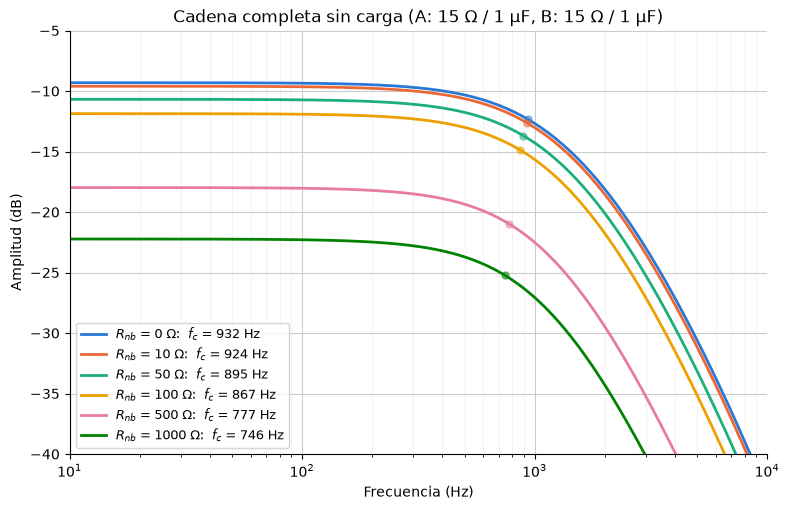

In [9]:
R_nb_lista = [0, 10, 50, 100, 500, 1000]   # Ω, en cada alambre

fig, ax = plt.subplots(figsize=(9, 5.5))
for R in R_nb_lista:
    H = lambda fr: H_cadena(fr, ABIERTO, R_nb=R)
    fc = frecuencia_corte(H)
    linea, = ax.semilogx(f, curva_dB(H, f), label=f"$R_{{nb}}$ = {R:g} Ω:  $f_c$ = {fc:.0f} Hz")
    nivel_fc = en_dB(H(F_BAJA)) - CAIDA_3dB
    ax.plot(fc, nivel_fc, "o", markersize=5, alpha=0.5, color=linea.get_color())   # punto en la f_c

ax.set_xlim(10, 1e4)
ax.set_ylim(-40, -5)
ax.set_xlabel("Frecuencia (Hz)")
ax.set_ylabel("Amplitud (dB)")
ax.set_title(f"Cadena completa sin carga (A: {AMB_A}, B: {AMB_B})")
cuadricula(ax)
ax.legend(fontsize=9)
plt.show()

### 4.3 $f_c$ según la resistencia del Nb (0 a 1000 Ω)
$f_c$ para 101 valores de resistencia del Nb entre 0 y 1000 Ω, con crio y sin crio (el crio
reemplazado por cables). El punto negro es la pieza en caliente, según `L_nb` y `d_nb`.

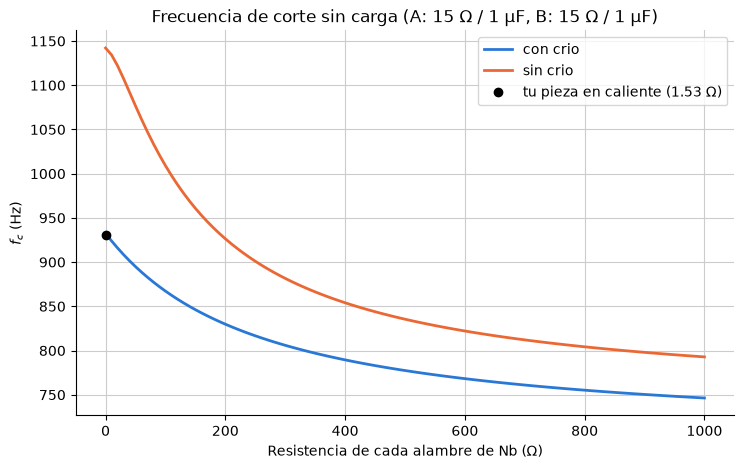

R_nb =     0 Ω:  f_c =  932.5 Hz  ( +0.0 % respecto de frío)
R_nb =    10 Ω:  f_c =  924.0 Hz  ( -0.9 % respecto de frío)
R_nb =    50 Ω:  f_c =  894.9 Hz  ( -4.0 % respecto de frío)
R_nb =   100 Ω:  f_c =  867.2 Hz  ( -7.0 % respecto de frío)
R_nb =   500 Ω:  f_c =  777.4 Hz  (-16.6 % respecto de frío)
R_nb =  1000 Ω:  f_c =  746.3 Hz  (-20.0 % respecto de frío)


In [10]:
R_nb_barrido = np.linspace(0, 1000, 101)
fc_con = [fc_cadena(ABIERTO, R_nb=R) for R in R_nb_barrido]
fc_sin = [fc_cadena(ABIERTO, R_nb=R, crio=False) for R in R_nb_barrido]
fc_pieza = fc_cadena(ABIERTO, R_nb=R_nb_caliente)

fig, ax = plt.subplots(figsize=(8.5, 5))
ax.plot(R_nb_barrido, fc_con, label="con crio")
ax.plot(R_nb_barrido, fc_sin, label="sin crio")
ax.plot(R_nb_caliente, fc_pieza, "o", color="black", markersize=6,
        label=f"tu pieza en caliente ({R_nb_caliente:.2f} Ω)")
ax.set_xlabel("Resistencia de cada alambre de Nb (Ω)")
ax.set_ylabel("$f_c$ (Hz)")
ax.set_title(f"Frecuencia de corte sin carga (A: {AMB_A}, B: {AMB_B})")
cuadricula(ax)
ax.legend()
plt.show()

fc_frio = fc_cadena(ABIERTO)
for R in [0, 10, 50, 100, 500, 1000]:
    fcR = fc_cadena(ABIERTO, R_nb=R)
    print(f"R_nb = {R:5g} Ω:  f_c = {fcR:6.1f} Hz  ({100 * (fcR - fc_frio) / fc_frio:+5.1f} % respecto de frío)")

### 4.4 Resistencia de la pieza según largo y diámetro
$R_{nb} = \rho\,L / (\pi d^2/4)$, con la resistividad del Nb a temperatura ambiente
($\rho$ = 15 µΩ·cm). Cada casilla muestra la resistencia y la $f_c$ de la cadena con esa
pieza en caliente. En frío la resistencia es 0 Ω, sea cual sea el tamaño. Debajo de la tabla
está la cuenta para la pieza definida en los parámetros; los tamaños de la tabla se cambian
en `largos_mm` y `diametros_um`.

In [11]:
largos_mm = [5, 10, 20, 50, 100, 200]
diametros_um = [25, 50, 100, 250, 500]

def resistencia_nb(L_m, d_m):
    '''Resistencia de un alambre de Nb a temperatura ambiente (Ω).'''
    return rho_nb * L_m / (np.pi * d_m**2 / 4)

tabla = {}
for d in diametros_um:
    columna = []
    for L in largos_mm:
        R = resistencia_nb(L * 1e-3, d * 1e-6)
        columna.append(f"{R:.2f} Ω → {fc_cadena(ABIERTO, R_nb=R):.0f} Hz")
    tabla[f"d = {d} µm"] = columna

print(f"f_c con Nb frío (0 Ω): {fc_frio:.0f} Hz\n")
print(f"Tu pieza: L = {L_nb*1e3:g} mm, d = {d_nb*1e6:g} µm  →  R = {R_nb_caliente:.2f} Ω por alambre, "
      f"f_c = {fc_pieza:.0f} Hz ({100 * (fc_pieza - fc_frio) / fc_frio:+.2f} %)")

pd.DataFrame(tabla, index=[f"L = {L} mm" for L in largos_mm])

f_c con Nb frío (0 Ω): 932 Hz

Tu pieza: L = 20 mm, d = 50 µm  →  R = 1.53 Ω por alambre, f_c = 931 Hz (-0.14 %)


,d = 25 µm,d = 50 µm,d = 100 µm,d = 250 µm,d = 500 µm
L = 5 mm,1.53 Ω → 931 Hz,0.38 Ω → 932 Hz,0.10 Ω → 932 Hz,0.02 Ω → 932 Hz,0.00 Ω → 932 Hz
L = 10 mm,3.06 Ω → 930 Hz,0.76 Ω → 932 Hz,0.19 Ω → 932 Hz,0.03 Ω → 932 Hz,0.01 Ω → 932 Hz
L = 20 mm,6.11 Ω → 927 Hz,1.53 Ω → 931 Hz,0.38 Ω → 932 Hz,0.06 Ω → 932 Hz,0.02 Ω → 932 Hz
L = 50 mm,15.28 Ω → 920 Hz,3.82 Ω → 929 Hz,0.95 Ω → 932 Hz,0.15 Ω → 932 Hz,0.04 Ω → 932 Hz
L = 100 mm,30.56 Ω → 908 Hz,7.64 Ω → 926 Hz,1.91 Ω → 931 Hz,0.31 Ω → 932 Hz,0.08 Ω → 932 Hz
L = 200 mm,61.12 Ω → 888 Hz,15.28 Ω → 920 Hz,3.82 Ω → 929 Hz,0.61 Ω → 932 Hz,0.15 Ω → 932 Hz


### 4.5 Aporte del crio (sin carga, Nb frío)
Señal con crio y sin crio, y la diferencia entre las dos, que es la atenuación que agrega el
crio. Por debajo del piso de ruido del analizador ya no se puede medir.

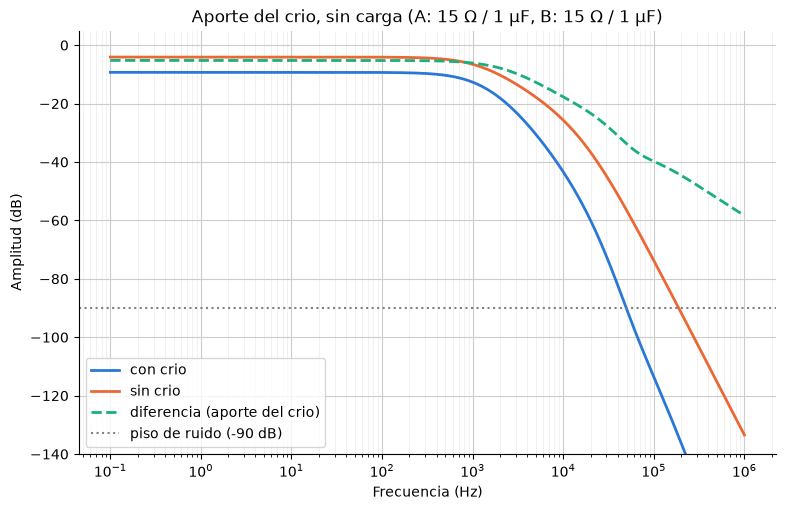

f_c con crio: 932 Hz, sin crio: 1142 Hz
La cadena con crio llega al piso de ruido cerca de 50 kHz
A    1 kHz el crio agrega   -6.1 dB
A   10 kHz el crio agrega  -17.7 dB
A   30 kHz el crio agrega  -27.6 dB


In [12]:
con_crio = curva_dB(lambda fr: H_cadena(fr, ABIERTO), f)
sin_crio = curva_dB(lambda fr: H_cadena(fr, ABIERTO, crio=False), f)

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.semilogx(f, con_crio, label="con crio")
ax.semilogx(f, sin_crio, label="sin crio")
ax.semilogx(f, con_crio - sin_crio, "--", label="diferencia (aporte del crio)")
ax.axhline(PISO_RUIDO_dB, color="gray", linestyle=":", linewidth=1.5,
           label=f"piso de ruido ({PISO_RUIDO_dB:g} dB)")
ax.set_ylim(-140, 5)
ax.set_xlabel("Frecuencia (Hz)")
ax.set_ylabel("Amplitud (dB)")
ax.set_title(f"Aporte del crio, sin carga (A: {AMB_A}, B: {AMB_B})")
cuadricula(ax)
ax.legend()
plt.show()

print(f"f_c con crio: {fc_cadena(ABIERTO):.0f} Hz, sin crio: {fc_cadena(ABIERTO, crio=False):.0f} Hz")
print(f"La cadena con crio llega al piso de ruido cerca de {f[np.argmax(con_crio < PISO_RUIDO_dB)]/1e3:.0f} kHz")
for x in [1e3, 1e4, 3e4]:
    i = np.argmin(abs(f - x))
    print(f"A {x/1e3:4.0f} kHz el crio agrega {con_crio[i] - sin_crio[i]:6.1f} dB")

### 4.6 Las 6 configuraciones del ambiente (A y B iguales, sin carga)
$f_c$ con crio (Nb frío y Nb caliente), $f_c$ sin crio y nivel de señal a baja frecuencia
para cada configuración del ambiente.

In [13]:
filas = []
for conf in CONFIGS_AMB:
    op = dict(amb_A=conf, amb_B=conf)
    filas.append({
        "configuración": conf,
        "f_c con crio, Nb frío (Hz)": round(fc_cadena(ABIERTO, **op), 1),
        "f_c con crio, Nb caliente (Hz)": round(fc_cadena(ABIERTO, R_nb=R_nb_caliente, **op), 1),
        "f_c sin crio (Hz)": round(fc_cadena(ABIERTO, crio=False, **op), 1),
        "nivel a baja f (dB)": round(nivel_bajo(ABIERTO, **op), 2),
    })
pd.DataFrame(filas).set_index("configuración")

,"f_c con crio, Nb frío (Hz)","f_c con crio, Nb caliente (Hz)",f_c sin crio (Hz),nivel a baja f (dB)
configuración,,,,
"150 Ω / 2,2 µF",134.2,134.1,141.8,-18.40
150 Ω / 1 µF,286.0,285.9,312.0,-18.40
"51 Ω / 2,2 µF",273.6,273.3,304.5,-12.79
51 Ω / 1 µF,584.6,584.0,670.0,-12.79
"15 Ω / 2,2 µF",434.9,434.3,519.1,-9.31
15 Ω / 1 µF,932.5,931.1,1142.1,-9.31


## 5. Conclusiones
Ambiente 15 Ω / 1 µF en A y B, sin carga entre + y −.

1. El tamaño de la pieza de Nb casi no importa. En frío es 0 Ω, sea cual sea el tamaño. En
   caliente, cualquier pieza razonable (milímetros a centímetros de largo, 25 µm o más de
   diámetro) tiene pocos ohms, y la $f_c$ cambia menos de 1–2 % (por ejemplo, 20 mm × 50 µm:
   1,5 Ω, 932 → 931 Hz).
2. La resistencia del Nb empieza a notarse recién arriba de unas decenas de ohms (50 Ω: −4 %;
   1000 Ω: −20 %), porque la señal ya pasa por unos 290 Ω en serie (generador, filtros y
   analizador).
3. El crio se nota en la medición: la $f_c$ baja de 1142 Hz (sin crio) a 932 Hz (con crio), y
   a 10 kHz el crio agrega unos 18 dB de atenuación. La señal llega al piso de ruido (−90 dB)
   cerca de 50 kHz.
4. Conviene usar el ambiente de $f_c$ más alta (15 Ω / 1 µF). Con 150 Ω / 2,2 µF el ambiente
   corta tan abajo que el crio casi no se ve (142 → 134 Hz).
5. El ambiente medido con 50 Ω no corta en su valor de diseño (150/2,2 da 608 Hz, no 180),
   así que las mediciones hay que compararlas contra la simulación con 50 Ω.